# Lab 2 — Ciclo de treino, vazamento e métricas
**João Rietra · BD-P4-2026.2 · Individual · 1,0 ponto na AV1**

Base: Red Wine Quality. Código em `lab02lib/` (gráficos em `graficos.py`); mapa no `README.md`. Os números dos títulos saem do código.

```mermaid
flowchart TD
    A["CSV Red Wine Quality<br/>usa: só leitura"]:::dev --> B["alvo (nota ≥ 7) e grupo_perfil<br/>usa: nenhuma partição"]:::dev
    B --> C["B2: separa por grupo_perfil<br/>treino, validação e teste"]:::dev
    C --> D["A: Dataset e loaders<br/>média e desvio: só treino"]:::dev
    D --> E["C e bônus: vazamento<br/>usa: treino + validação"]:::dev
    D --> F["D7: treino com parada antecipada<br/>usa: treino e validação"]:::dev
    F --> G["D5 e D6: limiar e calibração<br/>usa: validação"]:::dev
    G --> H["congela: json + hash dos pesos"]:::congela
    H --> I[["D1 a D3: métricas finais<br/>usa: teste (1x)"]]:::teste
    I --> J["D8: recomendação"]:::dev
    classDef dev fill:#F2F2F2,stroke:#404040,color:#1A1A1A
    classDef teste fill:#FFFFFF,stroke:#1A1A1A,stroke-width:4px,color:#1A1A1A
    classDef congela fill:#E3F2EC,stroke:#007A5A,stroke-width:2px,color:#1A1A1A
    classDef erro fill:#FBE8DB,stroke:#D55E00,stroke-width:2px,color:#1A1A1A
    classDef ok fill:#DDEBF5,stroke:#0072B2,stroke-width:2px,color:#1A1A1A
```

Quem pode ver o quê:

```mermaid
flowchart LR
    subgraph TR["treino"]
        a["estatísticas do z-score"]:::dev
        b["ajuste dos pesos"]:::dev
    end
    subgraph VA["validação"]
        c["parada antecipada"]:::dev
        d["escolha do limiar"]:::dev
    end
    subgraph TE["teste: só no fim, 1 vez"]
        e[["métricas finais"]]:::teste
    end
    a --> b --> c --> d --> e
    classDef dev fill:#F2F2F2,stroke:#404040,color:#1A1A1A
    classDef teste fill:#FFFFFF,stroke:#1A1A1A,stroke-width:4px,color:#1A1A1A
    classDef congela fill:#E3F2EC,stroke:#007A5A,stroke-width:2px,color:#1A1A1A
    classDef erro fill:#FBE8DB,stroke:#D55E00,stroke-width:2px,color:#1A1A1A
    classDef ok fill:#DDEBF5,stroke:#0072B2,stroke-width:2px,color:#1A1A1A
```

## 0. Ambiente
Abra na raiz do repositório (onde estão `apoio.py`, `dados/` e `lab02lib/`). CPU, dispositivo fixo em `'cpu'`.

In [1]:
from pathlib import Path
import sys, copy, time, json, importlib.metadata
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, Markdown
from apoio import FEATURES, carregar_base, fixar_semente, criar_modelo
from apoio import treinar_epoca, avaliar_perda, obter_escores
from lab02lib import MeuDataset, particionar_sem_vazar, treinar_com_parada
from lab02lib import tracking, graficos as gf   # tracking: registro opcional no MLflow (LAB02_TRACKING=0 desliga)

SEED = 42
fixar_semente(SEED)
DISPOSITIVO = 'cpu'
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0])
for pacote in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'torch']:
    print(pacote, importlib.metadata.version(pacote))

Python: 3.11.15
numpy 2.4.6
pandas 3.0.6
scikit-learn 1.9.1
matplotlib 3.11.2
torch 2.14.1


### Leitura da base
Só as colunas de `FEATURES` entram no modelo. Nada aqui aprende média, desvio ou partição.

In [2]:
base = carregar_base()
print(base.head().to_string(index=False))
print('\nLinhas:', len(base), '| características:', len(FEATURES))
print('Classe positiva:', int(base.alvo.sum()), '| proporção:', base.alvo.mean())
print('Perfis distintos:', base.grupo_perfil.nunique())
assert set(FEATURES).isdisjoint({'quality', 'alvo', 'id_linha', 'grupo_perfil'})

 fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density   pH  sulphates  alcohol  quality  alvo  id_linha         grupo_perfil
           7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978 3.51       0.56      9.4        5     0         0 16231909345439519184
           7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968 3.20       0.68      9.8        5     0         1  8814798900776851426
           7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970 3.26       0.65      9.8        5     0         2 16179437306182617678
          11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980 3.16       0.58      9.8        6     0         3  8450966096714587765
           7.4      

### Exemplo mínimo
Quatro observações artificiais, só para conferir o ambiente. A perda recebe o logit; a sigmoide só entra ao gerar escores.

In [3]:
x_exemplo = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_exemplo = torch.tensor([0., 0., 0., 1.])
exemplo_loader = DataLoader(TensorDataset(x_exemplo, y_exemplo), batch_size=2)
exemplo_modelo = criar_modelo(2).to(DISPOSITIVO)
exemplo_otimizador = torch.optim.Adam(exemplo_modelo.parameters(), lr=0.001)
exemplo_perda = treinar_epoca(exemplo_modelo, exemplo_loader, exemplo_otimizador,
                              nn.BCEWithLogitsLoss(), DISPOSITIVO)
print('Teste de ambiente concluído. Perda de treino artificial:', exemplo_perda)
del exemplo_modelo, exemplo_loader, exemplo_otimizador
fixar_semente(SEED)

Teste de ambiente concluído. Perda de treino artificial: 0.7283297479152679


## B2. Separe antes de normalizar
**Uso:** selecionar amostras de vinho tinto de nota alta com as 11 medidas. Semente 42, fixada antes de qualquer modelo; perfis idênticos ficam juntos.

```mermaid
flowchart TD
    A["base inteira"]:::dev --> B["GroupShuffleSplit 1<br/>por grupo_perfil, semente 42<br/>20% dos grupos"]:::dev
    B --> T[["teste<br/>cerca de 20% das linhas"]]:::teste
    B --> R["restante<br/>80% dos grupos"]:::dev
    R --> C["GroupShuffleSplit 2<br/>25% dos grupos do restante<br/>0,25 × 0,8 = 0,2 do total"]:::dev
    C --> V["validação<br/>cerca de 20%"]:::dev
    C --> TR["treino<br/>cerca de 60%"]:::dev
    TR --> AUD["auditoria: cobertura das linhas,<br/>id_linha sem repetição,<br/>0 perfis compartilhados por par,<br/>as duas classes em cada conjunto"]:::congela
    V --> AUD
    T --> AUD
    AUD --> ERR["qualquer falha levanta erro"]:::erro
    classDef dev fill:#F2F2F2,stroke:#404040,color:#1A1A1A
    classDef teste fill:#FFFFFF,stroke:#1A1A1A,stroke-width:4px,color:#1A1A1A
    classDef congela fill:#E3F2EC,stroke:#007A5A,stroke-width:2px,color:#1A1A1A
    classDef erro fill:#FBE8DB,stroke:#D55E00,stroke-width:2px,color:#1A1A1A
    classDef ok fill:#DDEBF5,stroke:#0072B2,stroke-width:2px,color:#1A1A1A
```

,conjunto,linhas,proporcao_linhas,desvio_pp_vs_alvo,positivos,negativos,proporcao_positiva,perfis
0,treino,961,0.6010,0.1001,139,822,0.1446,815
1,validacao,318,0.1989,-0.1126,33,285,0.1038,272
2,teste,320,0.2001,0.0125,45,275,0.1406,272


OK: auditoria sem falhas (cobertura, id_linha disjunto, 0 perfis compartilhados, duas classes em cada conjunto).


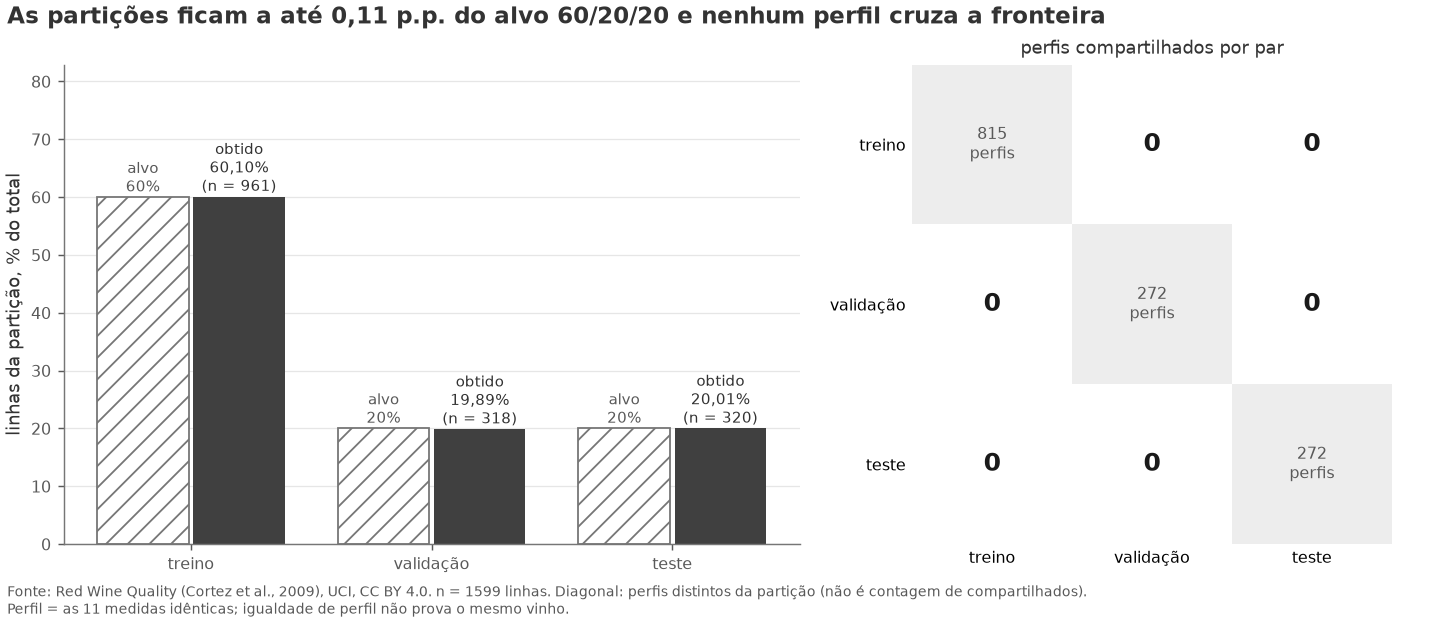

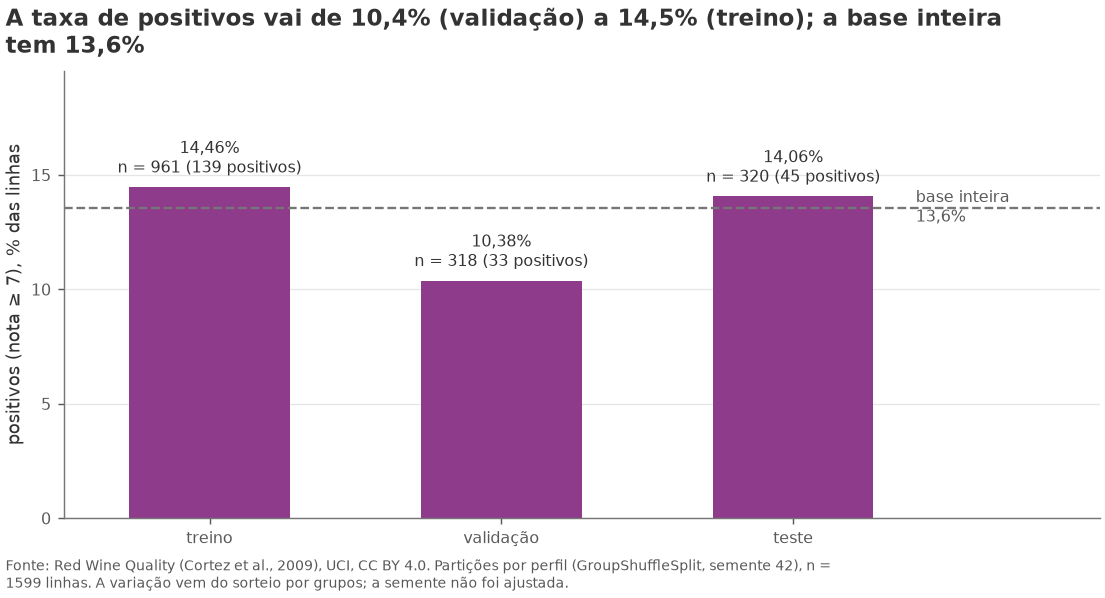

In [4]:
from lab02lib.split import auditar_particoes, PROPORCOES_ALVO

particoes = particionar_sem_vazar(base, SEED)
b2_tabela, b2_pares = auditar_particoes(particoes, base)
b2_tabela.to_csv(RESULTADOS / 'b2_auditoria.csv', index=False)
b2_pares.to_csv(RESULTADOS / 'b2_pares.csv', index=False)
display(b2_tabela.round(4))
print('OK: auditoria sem falhas (cobertura, id_linha disjunto, 0 perfis compartilhados, duas classes em cada conjunto).')
gf.publicar(gf.grafico_b2_particoes(b2_tabela, b2_pares, PROPORCOES_ALVO),
           RESULTADOS / 'b2_particoes.png')
gf.publicar(gf.grafico_b2_taxa_positiva(b2_tabela),
           RESULTADOS / 'b2_taxa_positiva.png')

### Primeiro olhar no treino
Só o treino: validação e teste ainda não foram olhados.

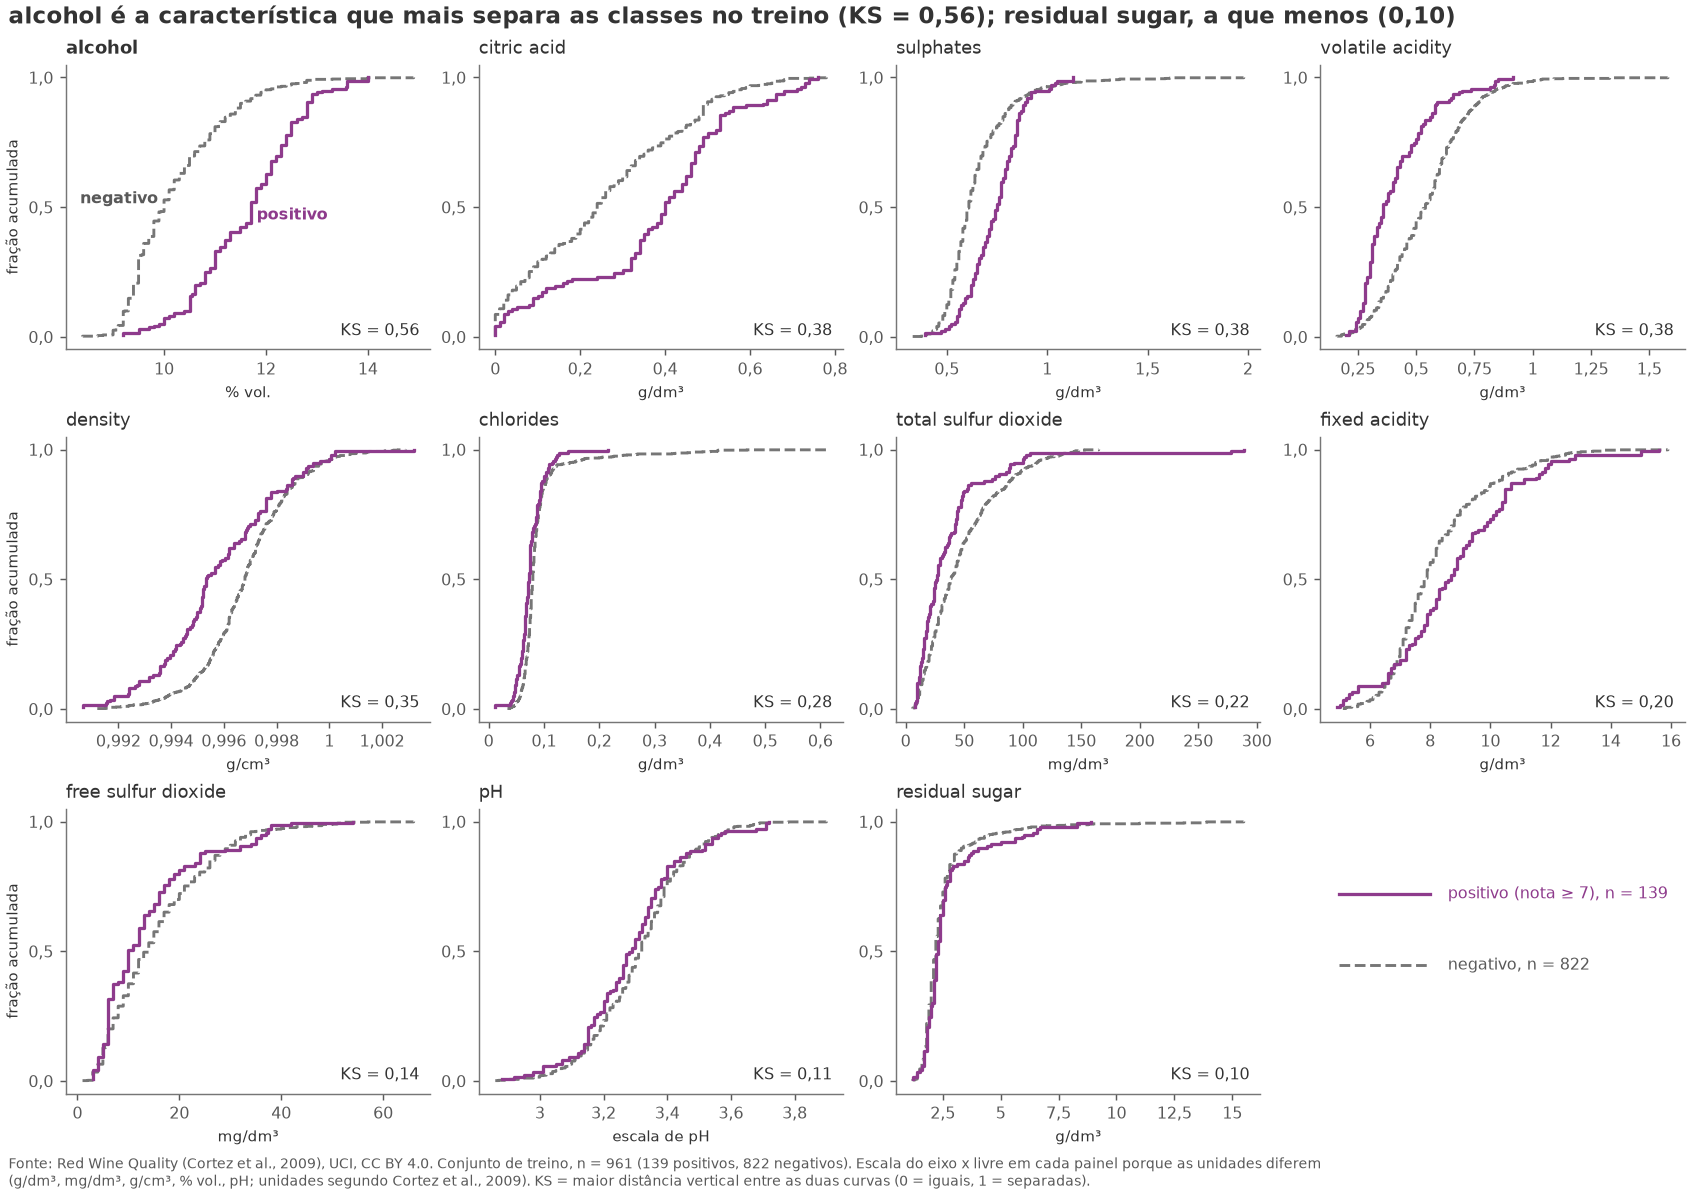

In [5]:
fig_eda, eda_ks = gf.grafico_eda(particoes['treino'], FEATURES)
eda_ks.to_csv(RESULTADOS / 'eda_ks.csv', index=False)
gf.publicar(fig_eda, RESULTADOS / 'eda_ecdf_treino.png')

### B1. Cinco cenários
No `README.md` (seção B1).

## A1. Dataset próprio
`MeuDataset` recebe uma partição, as características e, opcionalmente, média e desvio. No treino aprende as estatísticas; validação e teste usam as do treino (`ddof=0`, float64; desvio zero vira 1,0). Se a média usasse validação ou teste, seria a forma 1 de vazamento (Parte C). Exemplo: `X` float32 `[11]`, `y` float32 escalar; lote de B: `[B, 11]` e `[B]`.

In [6]:
from lab02lib.data import criar_datasets, criar_loaders, tabela_parametros, verificar_datasets

ds_treino, ds_validacao, ds_teste = criar_datasets(particoes, FEATURES)
print('Tamanhos: treino', len(ds_treino), '| validação', len(ds_validacao), '| teste', len(ds_teste))
print('\nDocstrings do MeuDataset:')
for nome in ['__init__', '__len__', '__getitem__']:
    print(f'- {nome}:', ' '.join(getattr(MeuDataset, nome).__doc__.split()))

Tamanhos: treino 961 | validação 318 | teste 320

Docstrings do MeuDataset:
- __init__: Prepara os tensores de ``df``. Se ``media`` e ``desvio`` não forem dados (instância de treino), eles são aprendidos só com as linhas de ``df``. Validação e teste recebem os valores do treino (``ds_treino.media`` e ``ds_treino.desvio``) e apenas os aplicam. Passar só um dos dois é erro. O alvo vem de ``df['alvo']``.
- __len__: Número de observações da partição.
- __getitem__: Devolve ``(X, y)`` da observação ``indice``: ``X`` float32 ``[11]``, ``y`` escalar float32.


### A2. Três DataLoaders
O treino embaralha (ordem nova a cada época, gerador semeado); validação e teste não embaralham nem descartam, para os escores seguirem a ordem dos rótulos.

,conjunto,batch_size,shuffle,drop_last,num_workers
0,treino,64,True,False,0
1,validacao,512,False,False,0
2,teste,512,False,False,0


OK: características não incluem quality, alvo, id_linha nem grupo_perfil.
OK: exemplo X (11,) torch.float32, y () torch.float32.
OK: todos os lotes têm forma [B, 11] / [B], float32, sem NaN ou infinito; nenhum carregador perde linhas.
OK: validação e teste usam exatamente a média e o desvio do treino (ddof=0).


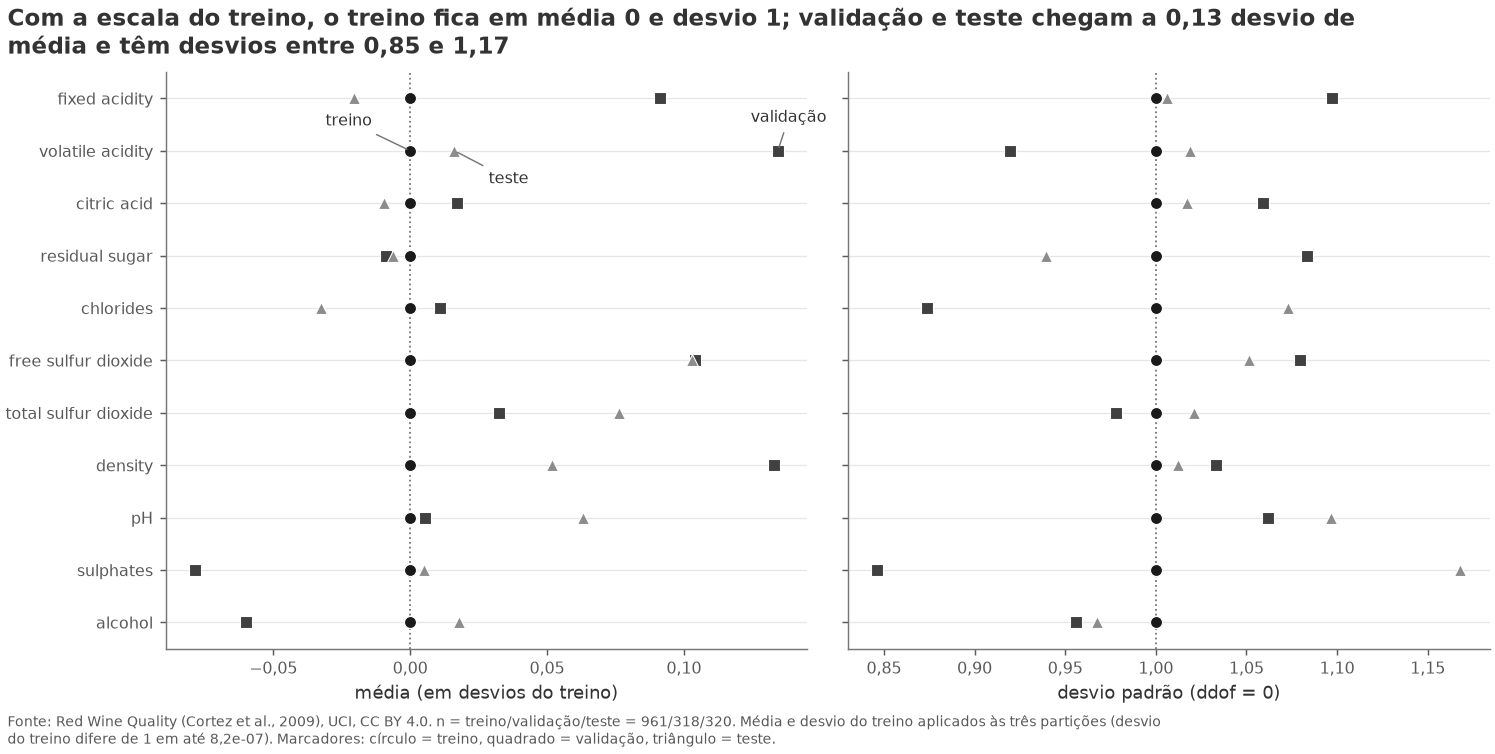

In [7]:
loader_treino, loader_validacao, loader_teste = criar_loaders(ds_treino, ds_validacao, ds_teste, SEED)
loaders = {'treino': loader_treino, 'validacao': loader_validacao, 'teste': loader_teste}
assert loader_validacao.dataset is ds_validacao and loader_teste.dataset is ds_teste
a2_tabela = tabela_parametros(loaders)
a2_tabela.to_csv(RESULTADOS / 'a2_loaders.csv', index=False)
display(a2_tabela)
a1_estatisticas = verificar_datasets(ds_treino, ds_validacao, ds_teste, loaders, FEATURES)
a1_estatisticas.to_csv(RESULTADOS / 'a1_estatisticas.csv', index=False)
gf.publicar(gf.grafico_normalizacao(gf.estatisticas_por_conjunto(
    {'treino': ds_treino, 'validacao': ds_validacao, 'teste': ds_teste}), FEATURES),
           RESULTADOS / 'a1_normalizacao.png')

In [8]:
display(Markdown(f'''| Conjunto | batch_size | shuffle | drop_last | num_workers | Efeito da escolha |
|---|---|---|---|---|---|
| treino | {loader_treino.batch_size} | {a2_tabela.shuffle[0]} | {loader_treino.drop_last} | {loader_treino.num_workers} | {len(loader_treino)} atualizações por época com {len(ds_treino)} linhas, meio-termo entre o lote 1 (muitas, ruidosas) e o 512 (poucas). Mantenho o último lote ({len(ds_treino) % 64} linha): sem BatchNorm, não quebra. |
| validação | {loader_validacao.batch_size} | {a2_tabela.shuffle[1]} | {loader_validacao.drop_last} | {loader_validacao.num_workers} | Sem gradientes, o lote só afeta memória; as {len(ds_validacao)} linhas cabem em um lote. |
| teste | {loader_teste.batch_size} | {a2_tabela.shuffle[2]} | {loader_teste.drop_last} | {loader_teste.num_workers} | Mesmo raciocínio ({len(ds_teste)} linhas); só é percorrido na avaliação final. |

`num_workers=0`: os dados já estão em tensores. **Não medi** workers maiores que 0, então não afirmo ganho nem perda.'''))

| Conjunto | batch_size | shuffle | drop_last | num_workers | Efeito da escolha |
|---|---|---|---|---|---|
| treino | 64 | True | False | 0 | 16 atualizações por época com 961 linhas, meio-termo entre o lote 1 (muitas, ruidosas) e o 512 (poucas). Mantenho o último lote (1 linha): sem BatchNorm, não quebra. |
| validação | 512 | False | False | 0 | Sem gradientes, o lote só afeta memória; as 318 linhas cabem em um lote. |
| teste | 512 | False | False | 0 | Mesmo raciocínio (320 linhas); só é percorrido na avaliação final. |

`num_workers=0`: os dados já estão em tensores. **Não medi** workers maiores que 0, então não afirmo ganho nem perda.

## A3. Tempo de uma época
Lotes 1, 8, 64 e 512 na rede **sem BatchNorm**; cada medida é uma época completa de `treinar_epoca`, cronometrada com `time.perf_counter()`. Modelo reconstruído do mesmo estado inicial, **Adam novo** e DataLoader novo a cada medida; uma época de aquecimento por tamanho; três repetições em rodízio; nada descartado.

,batch_size,repeticao,segundos,passos,exemplos,segundos_por_passo
0,1,1,0.27302,961,961,0.00028
1,8,1,0.04198,121,961,0.00035
2,64,1,0.00823,16,961,0.00051
3,512,1,0.00402,2,961,0.00201
4,1,2,0.26873,961,961,0.00028
5,8,2,0.04141,121,961,0.00034
6,64,2,0.00773,16,961,0.00048
7,512,2,0.00407,2,961,0.00203
8,1,3,0.26715,961,961,0.00028
9,8,3,0.04136,121,961,0.00034


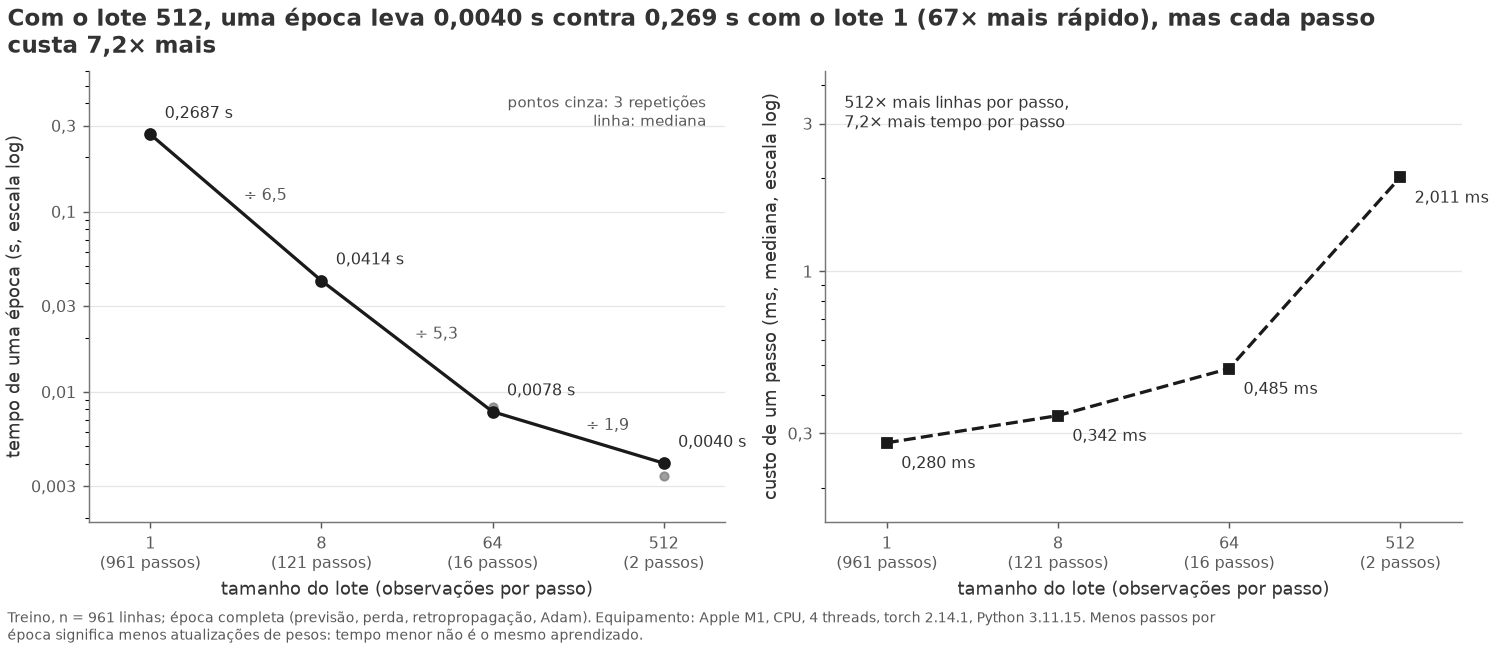

In [9]:
from lab02lib.timing import medir_tempos, resumir_tempos, descrever_hardware

hardware = descrever_hardware()
tempos = medir_tempos(ds_treino, [1, 8, 64, 512], repeticoes=3, semente=SEED, dispositivo=DISPOSITIVO)
a3_resumo = resumir_tempos(tempos)
pd.DataFrame(tempos).to_csv(RESULTADOS / 'a3_tempos.csv', index=False)
a3_resumo.to_csv(RESULTADOS / 'a3_resumo.csv', index=False)
(RESULTADOS / 'a3_hardware.json').write_text(json.dumps(hardware, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.DataFrame(tempos).round(5))
gf.publicar(gf.grafico_tempos(tempos, hardware),
           RESULTADOS / 'a3_tempo_x_lote.png')

In [10]:
# Registro no MLflow só depois de terminar todas as medições (para não interferir nos tempos).
tracking.registrar_tempos(tempos, hardware, RESULTADOS)

## A4. BatchNorm com último lote 1
`BatchNorm1d` em `train()` precisa de mais de uma observação por lote. Uso 65 linhas do treino e lote 64 (65 % 64 = 1), `drop_last=False`, e capturo **só** esse `ValueError`. A correção roda com **modelo novo e a mesma semente** (o primeiro já deu um passo); um carregador espelho devolve o `id_linha` só para mostrar a linha descartada. Só vale para o treino: validação e teste usam `drop_last=False` e `eval()`.

```mermaid
flowchart TD
    A["65 linhas do treino, lote 64"]:::dev --> B["lote 1: 64 linhas<br/>lote 2: 1 linha"]:::dev
    B --> C["BatchNorm1d em train()<br/>com 1 linha"]:::erro
    C --> D["ValueError: Expected more than<br/>1 value per channel"]:::erro
    D --> E["correção: drop_last=True com shuffle=True<br/>modelo novo, mesma semente"]:::ok
    E --> F["o treino vê 64 de 65 linhas por época"]:::ok
    F --> G["a linha descartada muda a cada época<br/>porque embaralha antes de cortar"]:::ok
    classDef dev fill:#F2F2F2,stroke:#404040,color:#1A1A1A
    classDef teste fill:#FFFFFF,stroke:#1A1A1A,stroke-width:4px,color:#1A1A1A
    classDef congela fill:#E3F2EC,stroke:#007A5A,stroke-width:2px,color:#1A1A1A
    classDef erro fill:#FBE8DB,stroke:#D55E00,stroke-width:2px,color:#1A1A1A
    classDef ok fill:#DDEBF5,stroke:#0072B2,stroke-width:2px,color:#1A1A1A
```

Subconjunto de 65 linhas do treino, lote 64: resto 65 % 64 = 1.
OK: 65 % 64 == 1, o último lote terá uma única observação.
Sem correção (drop_last=False): 2 passos por época.
Erro capturado (ValueError): Expected more than 1 value per channel when training, got input size torch.Size([1, 16])
Tamanho do lote que falhou: 1 (lotes vistos antes dele: [64]).
Com correção (drop_last=True, shuffle=True): 1 passo por época, 64 de 65 linhas vistas.
Época 1: perda de treino 0.6314; linhas vistas: 64; linha descartada: id_linha=1318.
Época 2: perda de treino 0.6286; linhas vistas: 64; linha descartada: id_linha=688.
Época 3: perda de treino 0.6254; linhas vistas: 64; linha descartada: id_linha=567.
Linhas descartadas nas 3 épocas: [1318, 688, 567] (mudam entre épocas: True).


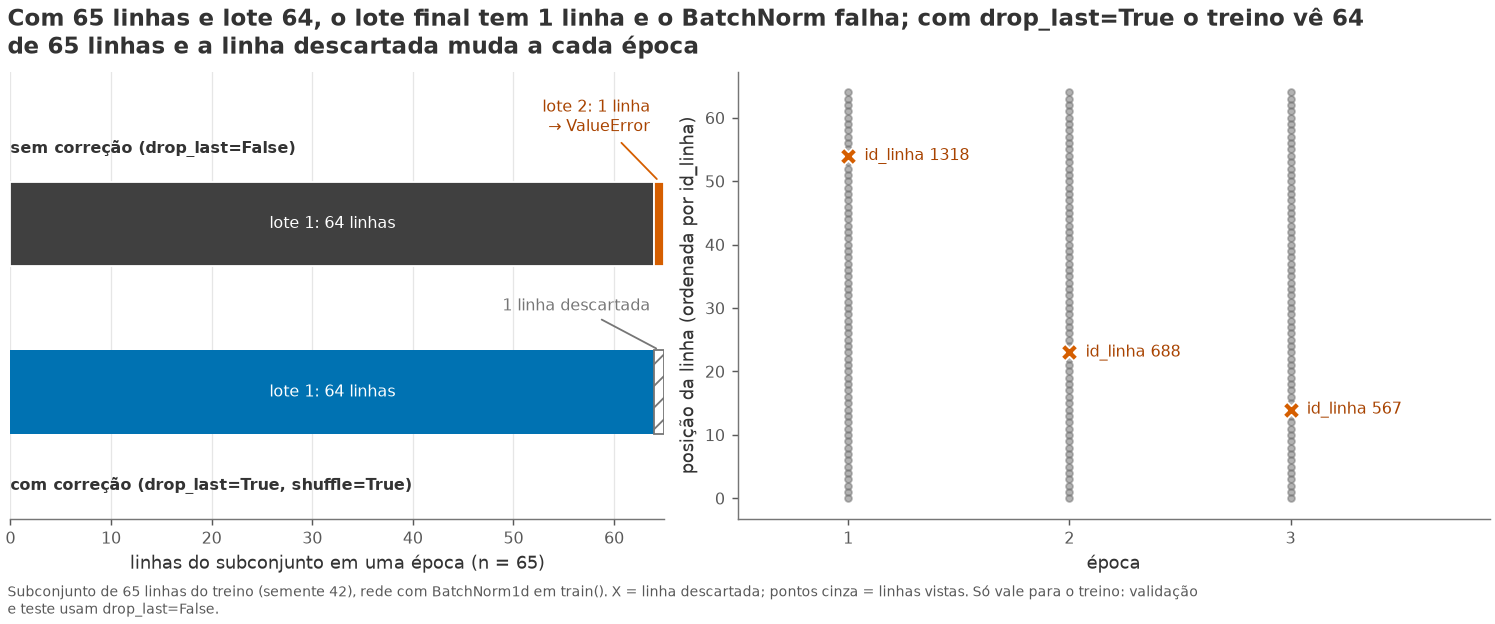

In [11]:
from lab02lib.batchnorm import demonstrar_batchnorm

a4 = demonstrar_batchnorm(ds_treino, RESULTADOS / 'a4_log.txt', semente=SEED)
gf.publicar(gf.grafico_batchnorm(a4),
           RESULTADOS / 'a4_batchnorm.png')

## C. Dois mecanismos de vazamento
Formas **1** (pré-processamento aprendido com dados reservados) e **4** (duplicatas entre aprendizagem e avaliação), com dados reais.

**Isolamento do teste.** Só `c_desenvolvimento = treino + validação`; um `assert` confere que nenhum `id_linha` do teste entra, e as variáveis da parte começam com `c_`.

**Protocolo (declarado antes de rodar).**
- Rede 11→16→1, `BCEWithLogitsLoss`, Adam 1e-3, lote 64, **100 épocas fixas**, sem parada antecipada.
- Métricas na avaliação interna: **acurácia (limiar 0,5)** e **AUC-ROC**.
- **Sementes 0 a 4**, nenhuma descartada. Incorreto e corrigido, na mesma semente, compartilham inicialização e embaralhamento.
- Diferença = `100 × (incorreto − corrigido)`: pontos percentuais na acurácia, AUC×100 na AUC-ROC. Desvio com `ddof=1`: **não é erro-padrão** (as partições se sobrepõem).
- **Forma 1.** Protegido: média e desvio da avaliação. Partição por perfil 75/25. *Expectativa antes de medir:* efeito perto de zero.
- **Forma 4.** Protegido: perfis da avaliação. O incorreto divide por linha (25%); o corrigido usa o **mesmo `E`** e tira do treino os perfis de `E` (treino menor, e mostro os dois tamanhos).

```mermaid
flowchart TD
    subgraph F1["Forma 1: pré-processamento"]
        a1["divisão por perfil 75/25"]:::dev --> b1["incorreto: média e desvio<br/>com treino + avaliação"]:::erro
        a1 --> c1["corrigido: média e desvio<br/>só do treino"]:::ok
    end
    subgraph F4["Forma 4: duplicatas"]
        a4["divisão por linha 75/25<br/>avaliação E"]:::dev --> b4["incorreto: o treino mantém<br/>perfis que estão em E"]:::erro
        a4 --> c4["corrigido: o treino perde os<br/>perfis de E (treino menor)"]:::ok
    end
    subgraph F8["Bônus: sobreamostragem"]
        a8["positivos a duplicar"]:::dev --> b8["incorreto: duplica e depois separa<br/>cópias dos dois lados"]:::erro
        a8 --> c8["corrigido: separa e depois duplica<br/>só os positivos do treino"]:::ok
    end
    classDef dev fill:#F2F2F2,stroke:#404040,color:#1A1A1A
    classDef teste fill:#FFFFFF,stroke:#1A1A1A,stroke-width:4px,color:#1A1A1A
    classDef congela fill:#E3F2EC,stroke:#007A5A,stroke-width:2px,color:#1A1A1A
    classDef erro fill:#FBE8DB,stroke:#D55E00,stroke-width:2px,color:#1A1A1A
    classDef ok fill:#DDEBF5,stroke:#0072B2,stroke-width:2px,color:#1A1A1A
```

In [12]:
from lab02lib.leakage import (c_desenvolvimento_de, executar_c, resumir_c, linhas_para_checagem,
                              tabela_enunciado, mecanismo_forma4, SEMENTES, FORMAS)

c_antes = set(globals())   # fotografia dos nomes, para provar que a parte C só criou nomes c_*
c_desenvolvimento = c_desenvolvimento_de(particoes)
c_ids_teste = set(particoes['teste']['id_linha'])
assert c_ids_teste.isdisjoint(c_desenvolvimento['id_linha'])
print('OK: nenhum id_linha do teste principal está em c_desenvolvimento ->', len(c_desenvolvimento), 'linhas (treino + validação).')
print('Sementes predeclaradas:', SEMENTES)

c_resultado = executar_c(c_desenvolvimento, SEMENTES)
c_resumo = resumir_c(c_resultado)
c_tabela = tabela_enunciado(c_resumo)
c_mecanismo = mecanismo_forma4(c_resultado)
resultados_c = linhas_para_checagem(c_resumo)
c_resultado.to_csv(RESULTADOS / 'c_resultados.csv', index=False)
c_resumo.to_csv(RESULTADOS / 'c_resumo.csv', index=False)
c_tabela.to_csv(RESULTADOS / 'c_tabela.csv', index=False)
c_mecanismo.to_csv(RESULTADOS / 'c_mecanismo_forma4.csv', index=False)
assert len(c_resultado) == len(SEMENTES) * 2 * 2
print('OK: 5 sementes × 2 formas × 2 variantes =', len(c_resultado), 'execuções; nenhuma descartada.')
display(c_resumo.round(4))

OK: nenhum id_linha do teste principal está em c_desenvolvimento -> 1279 linhas (treino + validação).
Sementes predeclaradas: (0, 1, 2, 3, 4)


OK: 5 sementes × 2 formas × 2 variantes = 20 execuções; nenhuma descartada.


,forma,metrica,incorreto_media,incorreto_desvio,corrigido_media,corrigido_desvio,diferenca_pp_media,diferenca_pp_desvio,diferenca_pp_min,diferenca_pp_max,sementes_com_diferenca_positiva,n_sementes
0,1,"acurácia (limiar 0,5)",0.8688,0.0097,0.8688,0.0097,0.0000,0.0000,0.0000,0.0000,0,5
1,1,AUC-ROC,0.8510,0.0155,0.8510,0.0157,0.0043,0.1562,-0.1054,0.2758,1,5
2,4,"acurácia (limiar 0,5)",0.8794,0.0137,0.8744,0.0146,0.5000,0.2795,0.3125,0.9375,5,5
3,4,AUC-ROC,0.8795,0.0166,0.8681,0.0222,1.1454,0.7806,0.5253,2.0108,5,5


In [13]:
tracking.registrar_vazamento(c_resultado, RESULTADOS)   # uma execução por forma × variante × semente

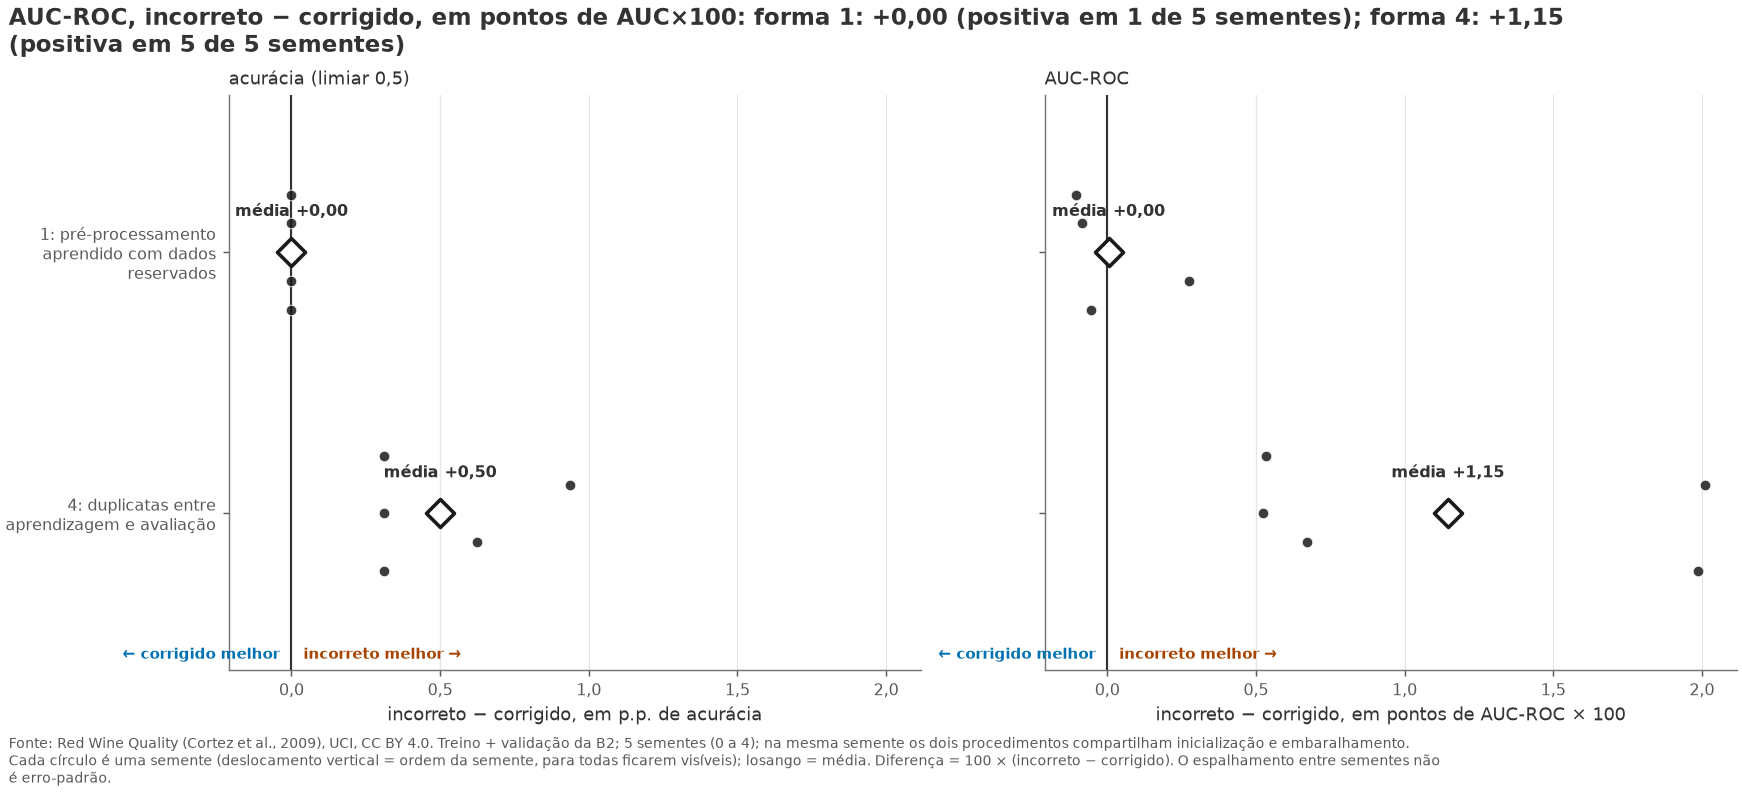

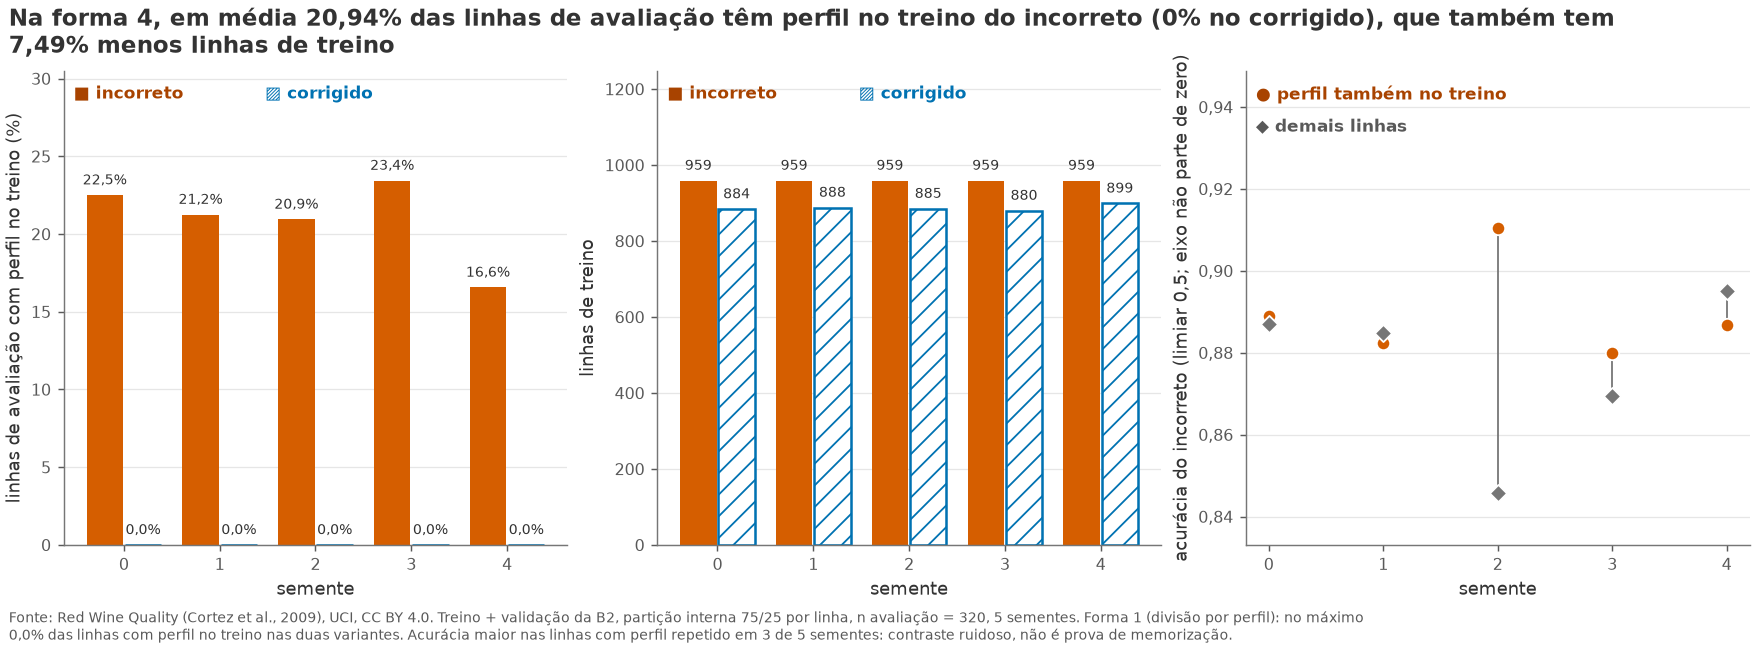

In [14]:
gf.publicar(gf.grafico_diferencas(c_resultado, FORMAS, gf.METRICAS_C),
           RESULTADOS / 'c_diferencas.png')
gf.publicar(gf.grafico_mecanismo_forma4(c_resultado),
           RESULTADOS / 'c_mecanismo_forma4.png')

In [15]:
c_novos = {n for n in set(globals()) - c_antes if not n.startswith('_') and n not in ('In', 'Out', 'c_antes')}
c_fora_do_padrao = sorted(n for n in c_novos if not n.startswith('c_') and n != 'resultados_c')
assert not c_fora_do_padrao, c_fora_do_padrao
print('OK: toda variável criada na parte C começa com c_ (exceto resultados_c, exigida pela conferência final).')

OK: toda variável criada na parte C começa com c_ (exceto resultados_c, exigida pela conferência final).


## D7. Rede principal com parada antecipada
Rede nova (11→16→1, ReLU), semente 42, nada herdado da C: a primeira célula **apaga as variáveis `c_`**. Fixados antes: `max_epocas=100`, `paciencia=10`, `min_delta=1e-4`. A função **não recebe o loader de teste** (assinatura conferida).

```mermaid
flowchart TD
    A["nova época: treina no treino"]:::dev --> B["perda de validação<br/>sem gradientes"]:::dev
    B --> C{"perda_val menor que<br/>melhor − min_delta?"}
    C -->|sim| D["deepcopy do state_dict<br/>guarda época e perda<br/>paciência volta a 0"]:::ok
    C -->|não| E["paciência + 1"]:::dev
    D --> G{"chegou a max_epocas?"}
    E --> F{"paciência chegou<br/>ao limite?"}
    F -->|não| G
    F -->|sim| H["para o treino"]:::erro
    G -->|não| A
    G -->|sim| H
    H --> I["restaura os melhores pesos<br/>load_state_dict"]:::congela
    classDef dev fill:#F2F2F2,stroke:#404040,color:#1A1A1A
    classDef teste fill:#FFFFFF,stroke:#1A1A1A,stroke-width:4px,color:#1A1A1A
    classDef congela fill:#E3F2EC,stroke:#007A5A,stroke-width:2px,color:#1A1A1A
    classDef erro fill:#FBE8DB,stroke:#D55E00,stroke-width:2px,color:#1A1A1A
    classDef ok fill:#DDEBF5,stroke:#0072B2,stroke-width:2px,color:#1A1A1A
```

OK: variáveis c_ removidas. A parte D usa só particoes, os datasets e os carregadores da B2/A.
Parâmetros de treinar_com_parada: ['modelo', 'loader_treino', 'loader_validacao', 'max_epocas', 'paciencia', 'min_delta', 'dispositivo', 'lr'] (nenhum é carregador de teste)


OK: pesos restaurados iguais ao melhor estado; perda de validação recalculada confere (< 1e-6).


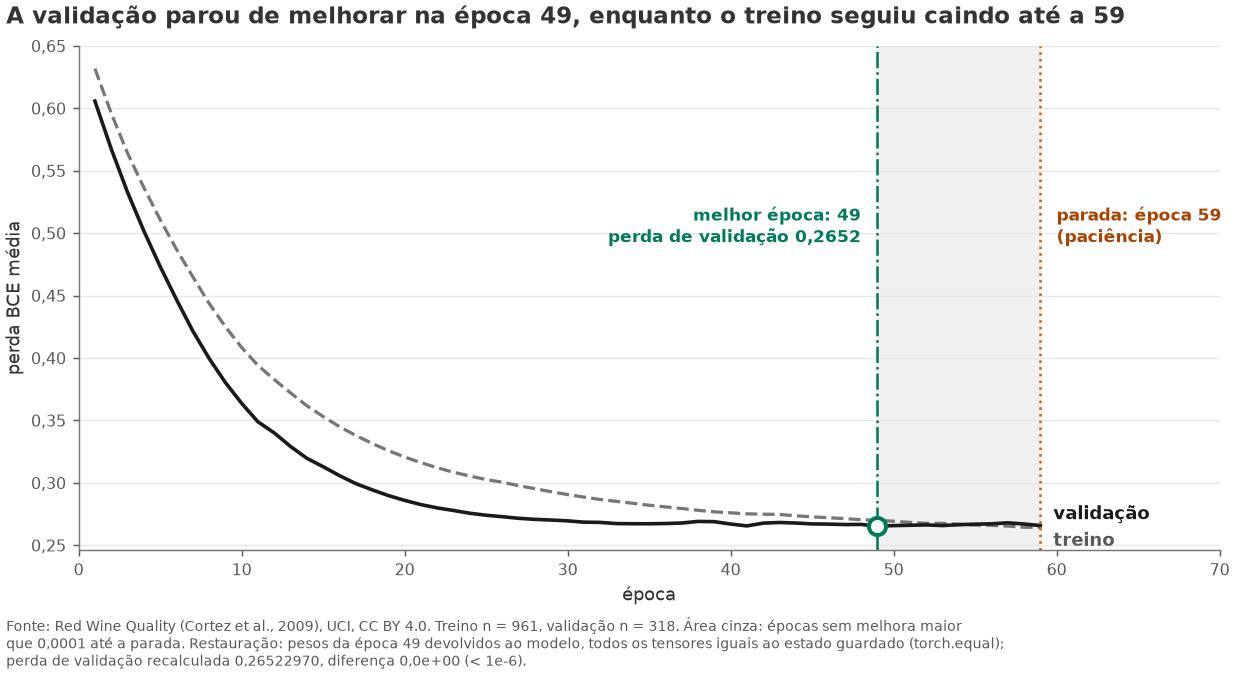

In [16]:
from lab02lib.train import assinatura_sem_teste, verificar_restauracao

for nome in [n for n in list(globals()) if n.startswith('c_')]:
    del globals()[nome]
assert not [n for n in globals() if n.startswith('c_')]
print('OK: variáveis c_ removidas. A parte D usa só particoes, os datasets e os carregadores da B2/A.')
print('Parâmetros de treinar_com_parada:', assinatura_sem_teste(), '(nenhum é carregador de teste)')

fixar_semente(SEED)
loader_treino.generator.manual_seed(SEED)   # o embaralhamento do treino recomeça da semente
modelo_final = criar_modelo(11).to(DISPOSITIVO)
resultado_d7 = treinar_com_parada(modelo_final, loader_treino, loader_validacao,
                                  max_epocas=100, paciencia=10, min_delta=0.0001)
historico = resultado_d7.historico
historico.to_csv(RESULTADOS / 'd7_historico.csv', index=False)
prova = verificar_restauracao(modelo_final, resultado_d7, loader_validacao, DISPOSITIVO)
print('OK: pesos restaurados iguais ao melhor estado; perda de validação recalculada confere (< 1e-6).')
gf.publicar(gf.grafico_perdas(historico, resultado_d7.melhor_epoca, resultado_d7.epoca_parada, resultado_d7.motivo,
                  resultado_d7.melhor_perda, prova, len(ds_treino), len(ds_validacao)),
           RESULTADOS / 'd7_curvas_perda.png')

In [17]:
tracking.registrar_treino(historico, resultado_d7.melhor_epoca, resultado_d7.epoca_parada, resultado_d7.motivo, RESULTADOS)

## D4. Custos como hipóteses
Prever positivo **seleciona** a amostra para análise especial. **FP:** selecionar uma de nota abaixo de 7. **FN:** deixar passar uma de nota pelo menos 7. Acertos custam zero. **`C_FP = 1` e `C_FN = 5`, em pontos de esforço: hipóteses do exercício**, a base não traz custo real.

Regra de desempate (fixada antes de ver os escores): entre limiares de custo mínimo igual, o mais próximo de 0,5; se ainda empatar, o menor. Positivo se escore >= limiar.


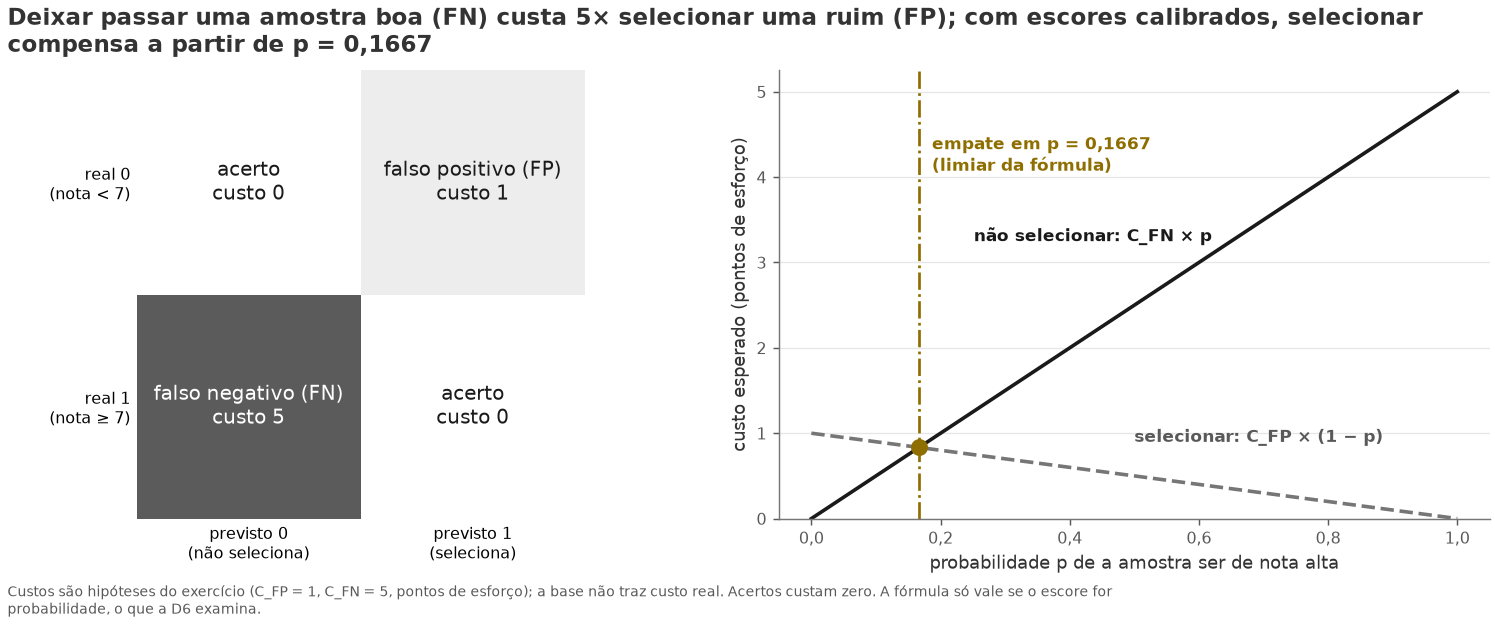

In [18]:
from lab02lib.decision import C_FP, C_FN, REGRA_EMPATE
print('Regra de desempate (fixada antes de ver os escores):', REGRA_EMPATE)
gf.publicar(gf.grafico_custos(C_FP, C_FN),
           RESULTADOS / 'd4_matriz_custos.png')

## D5 e D6. Limiar na validação e fórmula
Com o melhor modelo restaurado, escores da **validação**; positivo se `escore >= limiar`, `custo = C_FP × FP + C_FN × FN`. Candidatos: todos os escores únicos mais um valor logo acima do máximo (`np.nextafter`); busca exata, não grade. **Desempate** (fixado antes): custo mínimo igual, o mais próximo de 0,5; se persistir, o menor. Comparo com 0,5, a fórmula, tudo positivo e tudo negativo.

**Aviso.** A validação já decidiu a parada e agora decide o limiar: evidência de desenvolvimento, **não** a estimativa final.

OK: escores e rótulos da validação alinhados; 318 observações, 33 positivos.


,regra,limiar,fp,fn,custo_total,custo_por_obs
0,escolhido na busca,0.2766,33,9,78.0,0.2453
1,"padrão 0,5",0.5000,12,25,137.0,0.4308
2,fórmula C_FP/(C_FP+C_FN),0.1667,56,8,96.0,0.3019
3,tudo positivo,NaN,285,0,285.0,0.8962
4,tudo negativo,NaN,0,33,165.0,0.5189


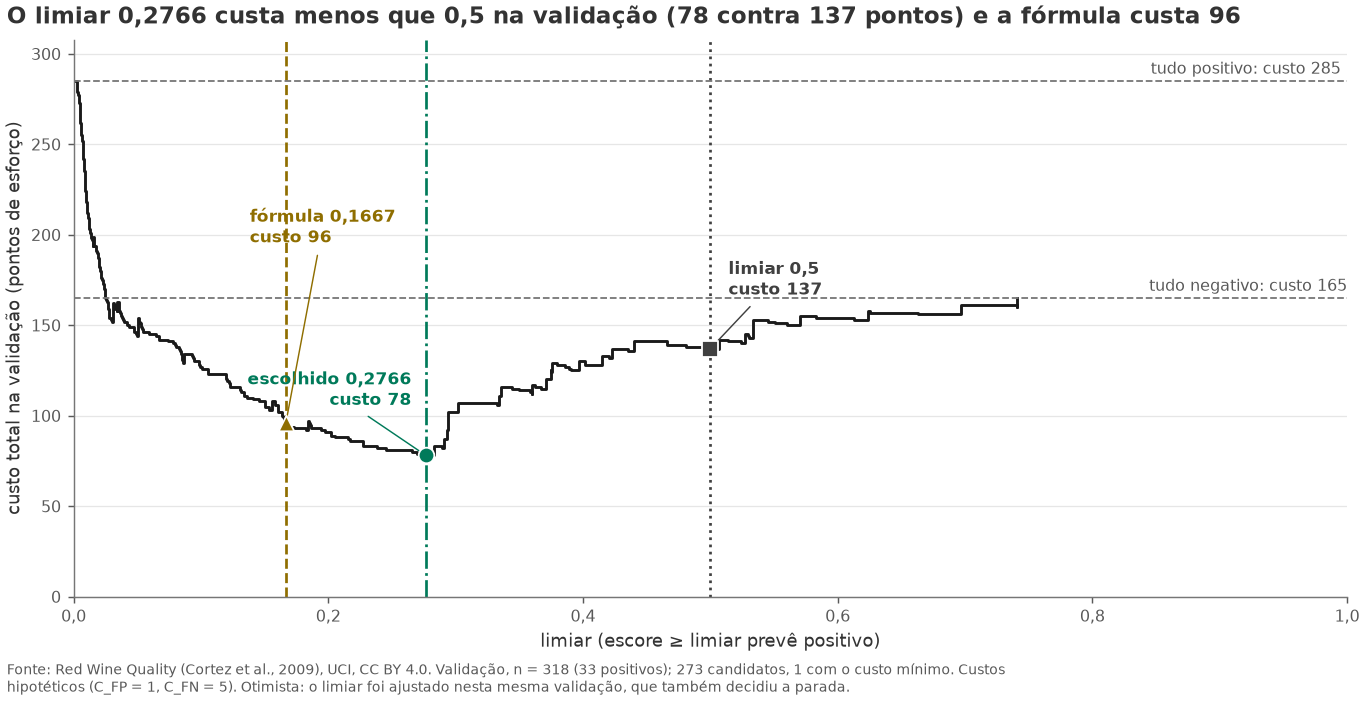

In [19]:
from lab02lib.decision import (buscar_limiar, comparar_regras, calibracao,
                               congelar, verificar_congelamento, prever)

y_val, p_val = obter_escores(modelo_final, loader_validacao, DISPOSITIVO)
assert loader_validacao.dataset is ds_validacao
assert np.array_equal(y_val, ds_validacao.y.numpy().astype(int)), 'rótulos desalinhados dos escores'
print('OK: escores e rótulos da validação alinhados;', len(y_val), 'observações,', int(y_val.sum()), 'positivos.')

busca = buscar_limiar(y_val, p_val)
busca.tabela.to_csv(RESULTADOS / 'd5_busca_limiar.csv', index=False)
d5_comparacao = comparar_regras(y_val, p_val, busca)
d5_comparacao.to_csv(RESULTADOS / 'd5_comparacao.csv', index=False)
limiar_escolhido = busca.limiar
display(d5_comparacao.round(4))
gf.publicar(gf.grafico_custo_limiar(busca, d5_comparacao, len(y_val), int(y_val.sum())),
           RESULTADOS / 'd5_curva_custo.png')

,bin,escore_medio,fracao_positivos
0,1,0.0064,0.0000
1,2,0.0167,0.0161
2,3,0.0482,0.0769
3,4,0.1483,0.0469
4,5,0.4241,0.3871


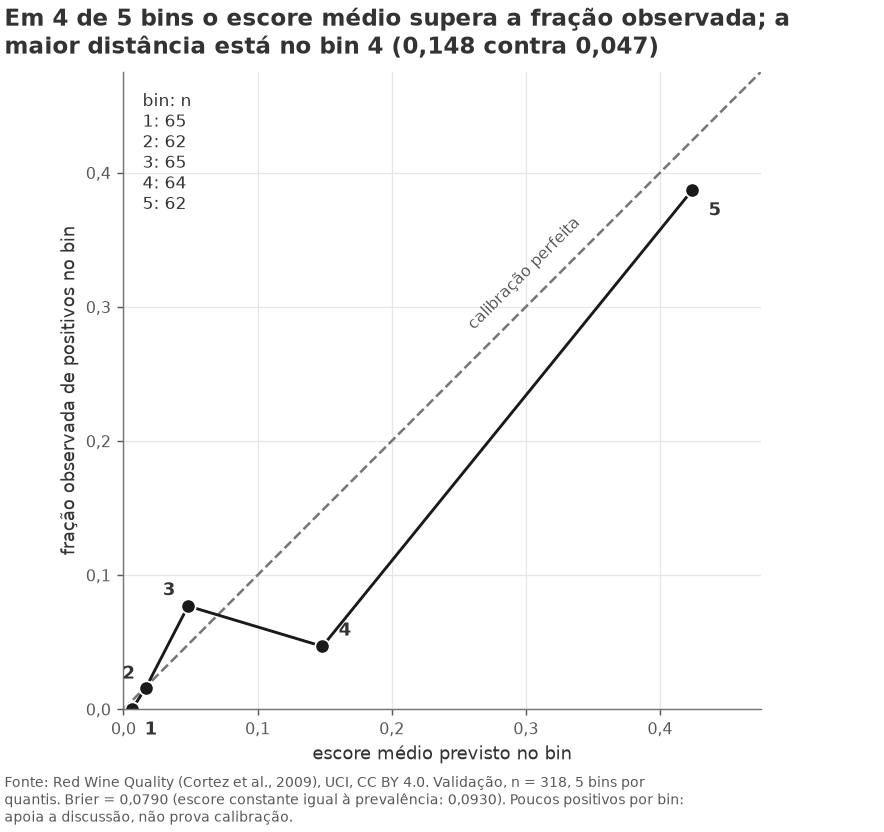

103

In [20]:
d6_tabela, d6_brier, d6_n = calibracao(y_val, p_val, n_bins=5)
d6_tabela.to_csv(RESULTADOS / 'd6_calibracao.csv', index=False)
display(d6_tabela.round(4))
prevalencia_val = float(y_val.mean())
gf.publicar(gf.grafico_calibracao(d6_tabela, d6_n, d6_brier, prevalencia_val * (1 - prevalencia_val), len(y_val)),
           RESULTADOS / 'd6_calibracao.png')
(RESULTADOS / 'd5_d6_meta.json').write_text(json.dumps(
    {'brier_validacao': d6_brier, 'n_candidatos': len(busca.tabela), 'n_limiares_com_custo_minimo': busca.n_empatados}, indent=2), encoding='utf-8')

**Por que a fórmula e a busca diferem?** Hipóteses, sem teste além do diagrama: poucos positivos na validação (a curva de custo é uma escada irregular); escores sem garantia de calibração; ausência de peso de classe. Não é resolução de grade, a busca é exata. Não ajusto o modelo para as duas respostas coincidirem.

### Congelando a decisão
Antes de abrir o teste gravo em `resultados/decisao_congelada.json` o limiar, o desempate, `C_FP`, `C_FN`, as características, média e desvio do treino, a arquitetura, a melhor época, o **SHA-256 dos pesos** e a semente.

```mermaid
flowchart TD
    A["busca exata na validação<br/>escores únicos + extremo tudo negativo"]:::dev --> B["desempate: mais próximo de 0,5,<br/>depois o menor"]:::dev
    B --> C["compara na validação: escolhido, 0,5,<br/>fórmula, tudo positivo, tudo negativo"]:::dev
    C --> D["grava decisao_congelada.json<br/>limiar, custos, estatísticas, SHA-256 dos pesos"]:::congela
    D --> E{"hash dos pesos e limiar<br/>iguais ao arquivo?"}
    E -->|não| F["recusa rodar o teste"]:::erro
    E -->|sim| G[["avalia o teste<br/>escores obtidos 1 vez"]]:::teste
    classDef dev fill:#F2F2F2,stroke:#404040,color:#1A1A1A
    classDef teste fill:#FFFFFF,stroke:#1A1A1A,stroke-width:4px,color:#1A1A1A
    classDef congela fill:#E3F2EC,stroke:#007A5A,stroke-width:2px,color:#1A1A1A
    classDef erro fill:#FBE8DB,stroke:#D55E00,stroke-width:2px,color:#1A1A1A
    classDef ok fill:#DDEBF5,stroke:#0072B2,stroke-width:2px,color:#1A1A1A
```

In [21]:
decisao = congelar(RESULTADOS / 'decisao_congelada.json', modelo_final, limiar_escolhido, ds_treino,
                   FEATURES, resultado_d7.melhor_epoca, SEED)
decisao_congelada = True
print('Decisão congelada: limiar =', decisao['limiar'], '| melhor época =', decisao['melhor_epoca'])
print('sha256 dos pesos =', decisao['sha256_pesos_restaurados'])

Decisão congelada: limiar = 0.2766464352607727 | melhor época = 49
sha256 dos pesos = bfc098ee58b67c8d6a1ea9eb7c19f26dd75a221023422ba9e2073bdf285b58f7


## D1, D2 e D3. Avaliação final
**Só agora o teste é aberto**, com a decisão congelada. Os escores saem **uma única vez** (um contador recusa a segunda chamada). Avalio 0,5, o limiar escolhido e o trivial.
- Matriz de confusão: **linhas = real, colunas = previsto**, ordem `[0, 1]`.
- AUC-ROC e AUC-PR vêm dos **escores** (iguais nas duas regras da rede). AUC-PR é trapezoidal, `auc(recall, precision)`; `average_precision_score` aparece à parte como **AP**.
- Sem previsão positiva, precisão = 0 (`zero_division=0`).
- Trivial: classe majoritária **do treino**; um preditor constante não tem ranking, então as AUCs ficam "não reportada".
- Custo por observação = `(C_FP×FP + C_FN×FN)/n`, em pontos hipotéticos.

In [22]:
from lab02lib.evaluate import EscoresUmaVez, avaliar_teste

assert decisao_congelada
verificar_congelamento(RESULTADOS / 'decisao_congelada.json', modelo_final, limiar_escolhido)
print('OK: o hash dos pesos e o limiar são os do arquivo congelado.')

obtentor = EscoresUmaVez(modelo_final, loader_teste, DISPOSITIVO)
y_teste, p_teste = obtentor.obter()
assert obtentor.chamadas == 1
assert np.array_equal(y_teste, ds_teste.y.numpy().astype(int))
print('OK: escores do teste obtidos exatamente', obtentor.chamadas, 'vez; rótulos alinhados com o dataset de teste.')

d_tabela, d_matrizes, areas = avaliar_teste(y_teste, p_teste, ds_treino.y.numpy().astype(int), limiar_escolhido)
avaliacao_final = d_tabela
d_tabela.to_csv(RESULTADOS / 'd_tabela_final.csv', index=False)
d_matrizes.to_csv(RESULTADOS / 'd_matrizes.csv', index=False)
(RESULTADOS / 'd_areas.json').write_text(json.dumps(areas, indent=2), encoding='utf-8')
display(d_tabela.round(4))

OK: o hash dos pesos e o limiar são os do arquivo congelado.
OK: escores do teste obtidos exatamente 1 vez; rótulos alinhados com o dataset de teste.


,regra,limiar,acuracia,precisao,revocacao,f1,auc_roc,auc_pr,custo_por_obs,fp,fn
0,Trivial do treino,não se aplica,0.8594,0.0000,0.0000,0.000,não reportada,não reportada,0.7031,0,45
1,Rede: padrão,0.5,0.8781,0.6667,0.2667,0.381,0.890747,0.564403,0.5344,6,33
2,Rede: escolhido na validação,0.276646,0.8562,0.4912,0.6222,0.549,0.890747,0.564403,0.3562,29,17


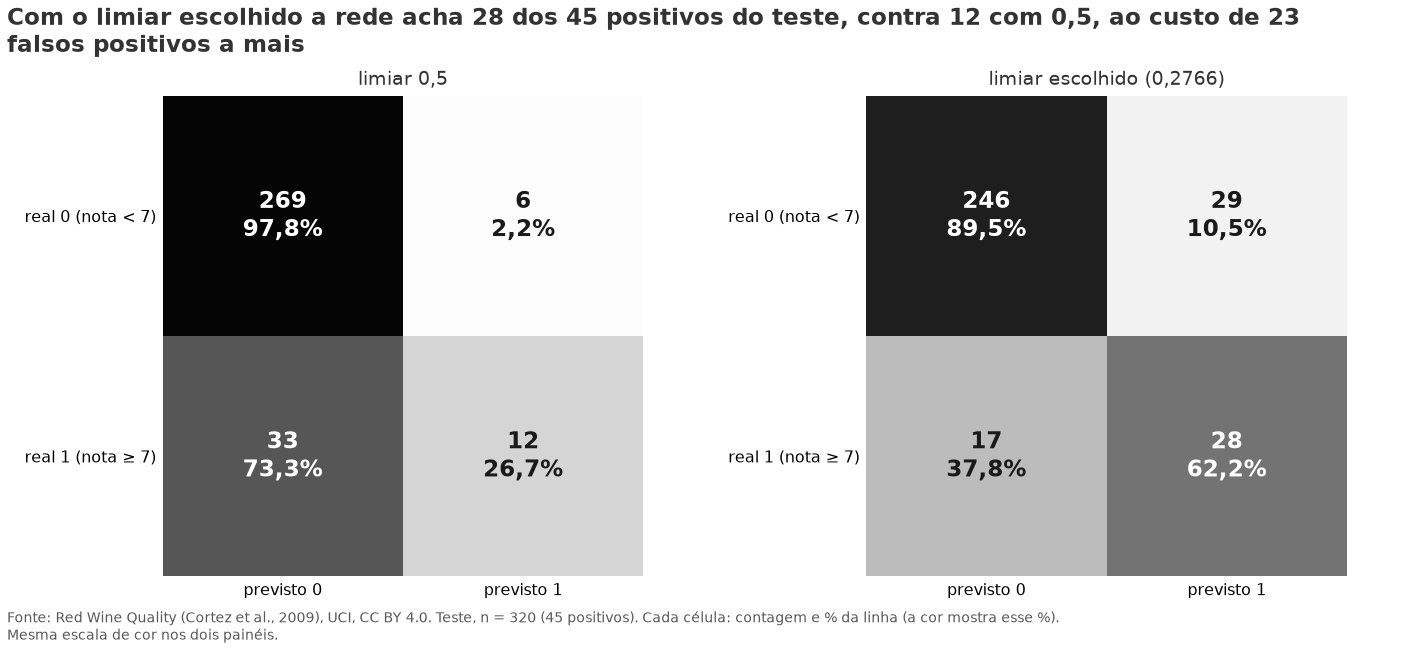

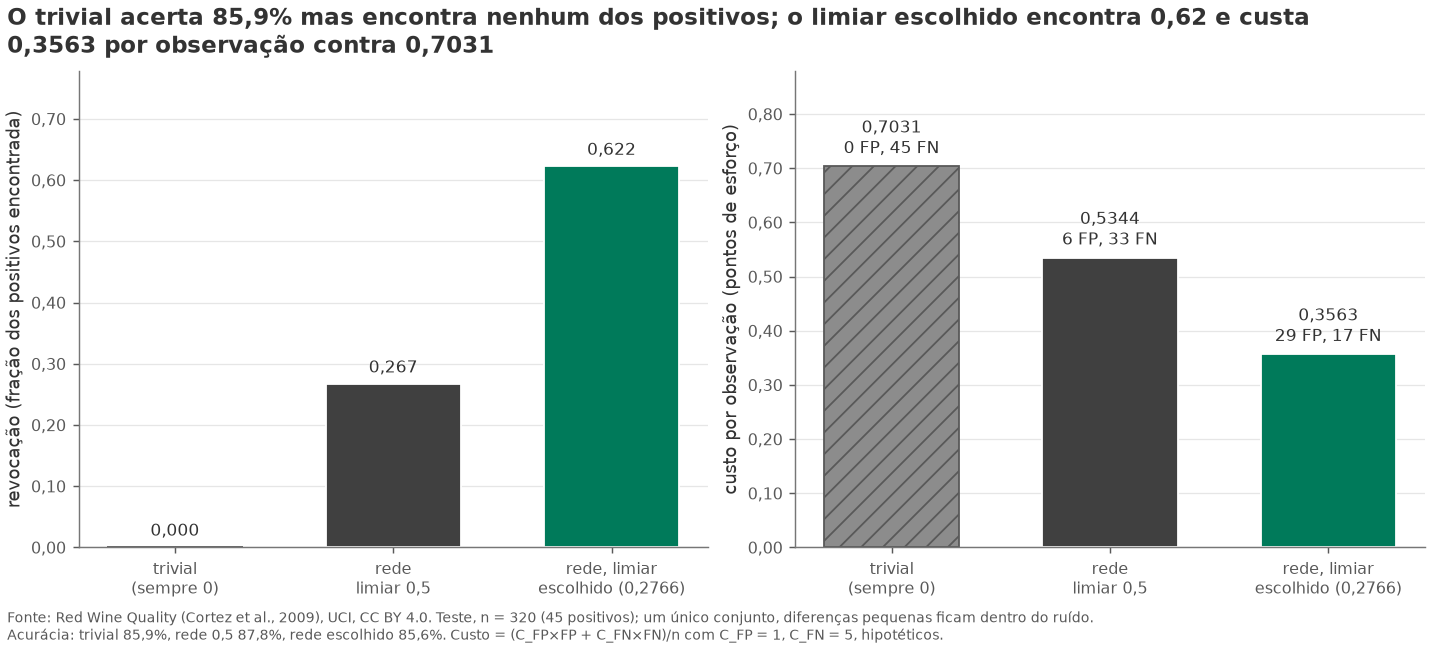

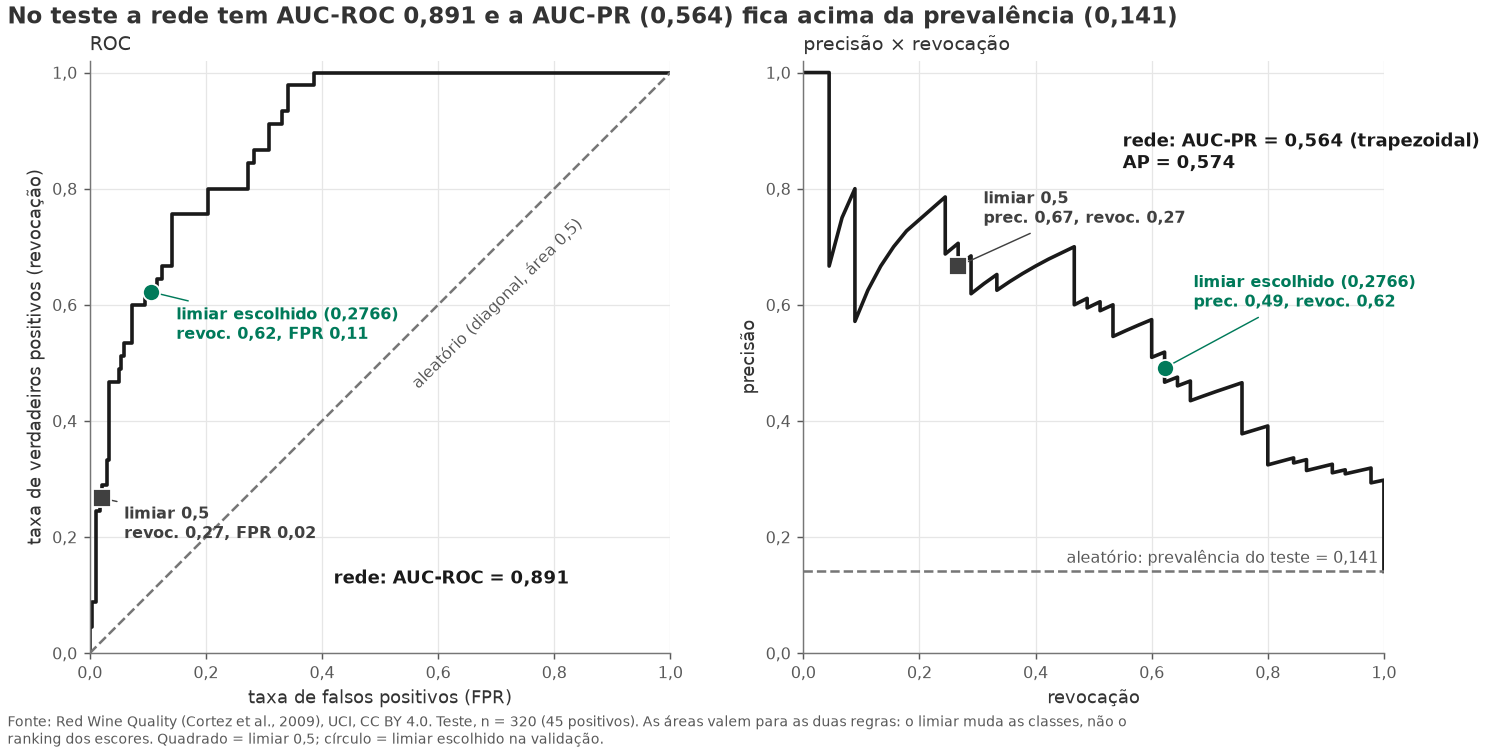

In [23]:
gf.publicar(gf.grafico_matrizes(d_matrizes, {'Rede: padrão': 'limiar 0,5',
                         'Rede: escolhido na validação': f'limiar escolhido ({gf.fmt(limiar_escolhido, 4)})'}),
           RESULTADOS / 'd2_matrizes.png')
gf.publicar(gf.grafico_regras(d_tabela, len(y_teste), int(y_teste.sum())),
           RESULTADOS / 'd2_regras.png')
gf.publicar(gf.grafico_roc_pr(y_teste, p_teste, limiar_escolhido, areas),
           RESULTADOS / 'd_curvas_roc_pr.png')

In [24]:
tracking.registrar_avaliacao(d_tabela, areas, limiar_escolhido, RESULTADOS)   # só registra; nada é decidido aqui

## D8. Recomendação final
O parágrafo está no `README.md` (seção D8). Os custos são **hipóteses** e nada vale para produtores, regiões ou períodos que a base não cobre.

## Bônus. Oitava forma: sobreamostragem antes de separar
*Seção independente: pode ser apagada sem mexer no resto.*

Duplicar positivos **antes** de separar põe cópias dos dois lados; ao contrário da forma 4, a duplicata é **fabricada** pelo pré-processamento. **Declarado antes:** mesmos dados, rede e sementes 0 a 4 da C, divisão por linha 75/25, cada positivo copiado **uma vez**, sem ajuste. A prevalência da avaliação difere entre as variantes, então leio a **AUC-ROC**.

OK: nenhum id_linha do teste em c_bonus_dev; 10 execuções (5 sementes × 2 variantes), nenhuma descartada.


,forma,metrica,incorreto_media,incorreto_desvio,corrigido_media,corrigido_desvio,diferenca_pp_media,diferenca_pp_desvio,diferenca_pp_min,diferenca_pp_max,sementes_com_diferenca_positiva,n_sementes
0,8,"acurácia (limiar 0,5)",0.8342,0.0154,0.8731,0.0151,-3.8965,1.0874,-5.4063,-2.8159,0,5
1,8,AUC-ROC,0.8828,0.0104,0.8881,0.0157,-0.5225,1.8630,-3.7369,0.8928,2,5


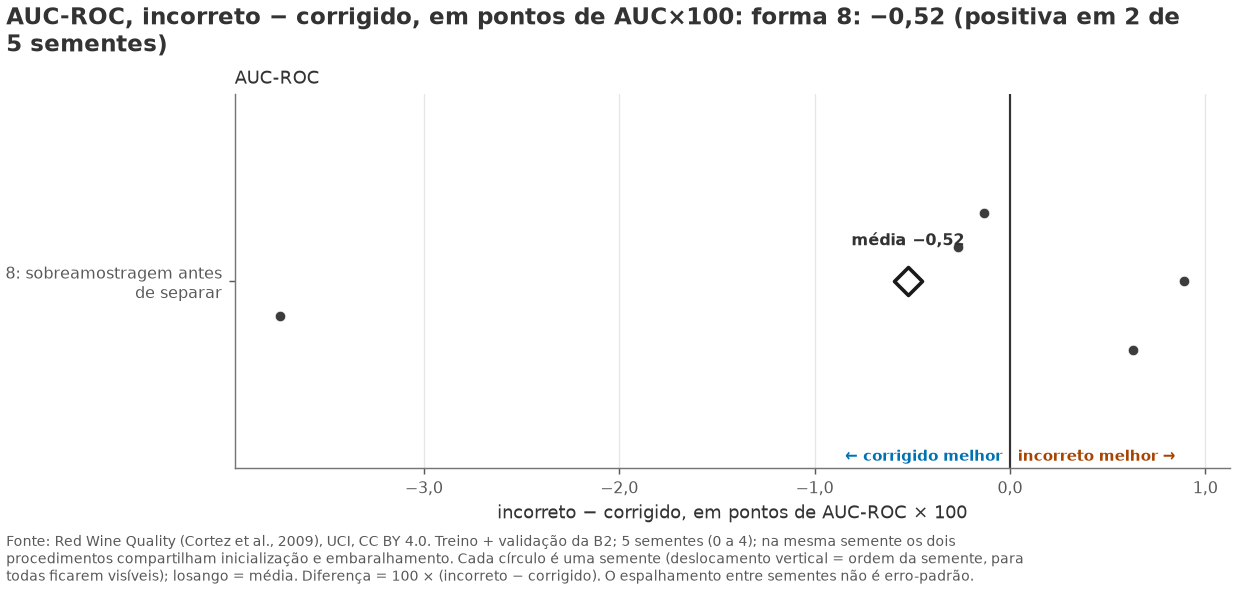

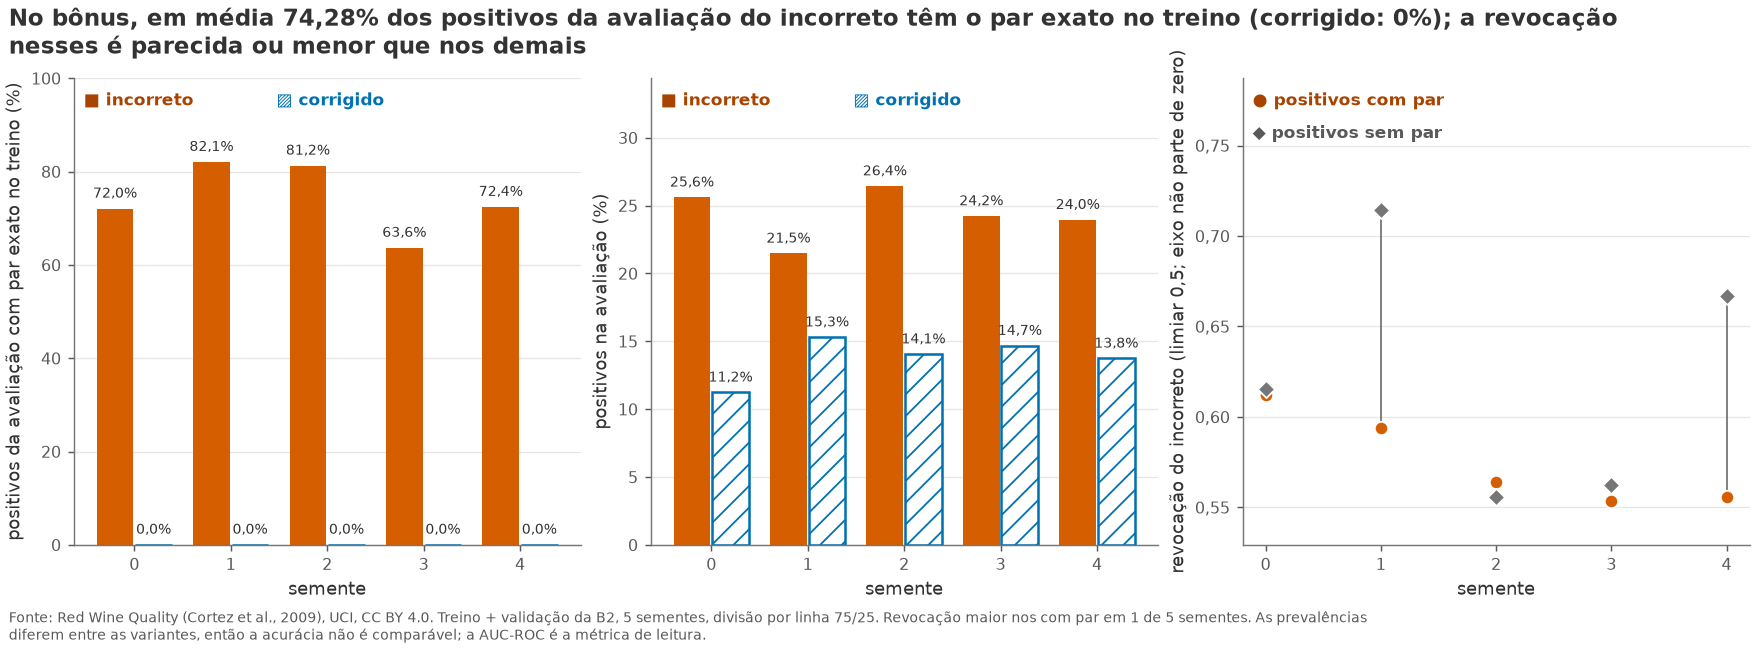

In [25]:
from lab02lib.bonus import executar_bonus_completo
from lab02lib.leakage import c_desenvolvimento_de, resumir_c

c_bonus_dev = c_desenvolvimento_de(particoes)    # de novo só treino + validação; assert de que o teste não entrou
c_bonus = executar_bonus_completo(c_bonus_dev)
c_bonus_resumo = resumir_c(c_bonus)
c_bonus.to_csv(RESULTADOS / 'bonus_resultados.csv', index=False)
c_bonus_resumo.to_csv(RESULTADOS / 'bonus_resumo.csv', index=False)
print('OK: nenhum id_linha do teste em c_bonus_dev;', len(c_bonus), 'execuções (5 sementes × 2 variantes), nenhuma descartada.')
display(c_bonus_resumo.round(4))
gf.publicar(gf.grafico_diferencas(c_bonus, {8: '8: sobreamostragem antes de separar'}, gf.METRICAS_BONUS),
           RESULTADOS / 'bonus_diferencas.png')
gf.publicar(gf.grafico_mecanismo_bonus(c_bonus),
           RESULTADOS / 'bonus_mecanismo.png')

## Auditoria da paleta
Contraste contra o branco, simulação de deuteranopia e luminosidade em cinza, calculados (função `auditar_paleta`).

In [26]:
paleta, paleta_pares = gf.auditar_paleta()
paleta.to_csv(RESULTADOS / 'paleta_auditoria.csv', index=False)
paleta_pares.to_csv(RESULTADOS / 'paleta_pares.csv', index=False)
assert paleta['passa'].all(), paleta[~paleta['passa']]
display(paleta)
display(paleta_pares)

,cor,hex,uso,contraste_vs_branco,minimo_exigido,passa,hex_deuteranopia,L_estrela
0,incorreto,#D55E00,gráfico,3.87,3.0,True,#9E8C00,54.2
1,corrigido,#0072B2,gráfico,5.19,3.0,True,#3B67B1,46.0
2,positivo,#8E3B8C,gráfico,6.66,3.0,True,#4F608A,39.2
3,escolhido,#007A5A,gráfico,5.34,3.0,True,#6A675C,45.2
4,formula,#8F6E00,gráfico,4.77,3.0,True,#85760B,48.2
5,modelo,#1A1A1A,gráfico,17.40,3.0,True,#1A1A1A,9.3
6,regra_05,#404040,gráfico,10.37,3.0,True,#404040,27.1
7,trivial,#8C8C8C,gráfico,3.36,3.0,True,#8C8C8C,58.3
8,referencia,#767676,gráfico,4.54,3.0,True,#767676,49.6
9,texto,#333333,texto,12.63,4.5,True,#333333,21.2


,cor_a,cor_b,onde,delta_E_deuteranopia,delta_L_cinza,so_cor_basta,reforco_nao_cromatico
0,incorreto,corrigido,"diferenças pareadas, mecanismo, bônus",108.4,8.2,False,preenchimento cheio × hachurado e rótulo direto
1,positivo,referencia,ECDF por classe; taxa de positivos,26.9,10.4,True,traço contínuo × tracejado e rótulo direto
2,trivial,regra_05,regras: revocação e custo,31.2,31.2,True,hachura no trivial e rótulo no eixo
3,regra_05,escolhido,"regras, matrizes, ROC/PR, custo",17.8,18.1,False,"quadrado × círculo, traço e rótulo direto"
4,trivial,escolhido,regras: revocação e custo,16.1,13.1,False,hachura no trivial e rótulo no eixo
5,escolhido,formula,curva de custo (D5),46.9,3.1,False,"traço-ponto × tracejado, marcador e rótulo direto"
6,regra_05,formula,curva de custo (D5),57.7,21.2,True,"pontilhado × tracejado, marcador e rótulo direto"
7,modelo,referencia,"perdas treino/validação, ROC/PR, calibração",40.4,40.4,True,contínuo × tracejado e rótulo direto
8,modelo,escolhido,ROC/PR: curva e regra escolhida,34.9,35.9,True,"curva × ponto, rótulo direto"


## Conferência da entrega
Esta célula imprime uma lista vazia.

In [27]:
pendencias = []
for nome, valor in [('particoes', particoes), ('ds_treino', ds_treino),
    ('loader_treino', loader_treino), ('historico', historico),
    ('limiar_escolhido', limiar_escolhido), ('avaliacao_final', avaliacao_final)]:
    if valor is None:
        pendencias.append(nome)
if not tempos: pendencias.append('tempos A3')
if len(resultados_c) < 2: pendencias.append('dois resultados C')
print('Pendências estruturais:', pendencias)

Pendências estruturais: []
